In [1]:
%pylab inline
import os
import gc
import matplotlib
import numpy as np
import astropy.io.fits as pyfits
import astropy.table as astTab
import massmap_utilities as mutilities
from configparser import ConfigParser
from pixel3D import cartesianGrid3D
from astropy.wcs import WCS
from scipy.stats import norm as statnorm
import matplotlib as mpl
import sim_analysis_utilities as utilities

Populating the interactive namespace from numpy and matplotlib


In [2]:
def mapPlot(pname,label,norm,raPList=None,decPList=None):
    assert (raPList is None)==(decPList is None)
    pltList=['XMM','VVDS','GAMA09H','GAMA15H','WIDE12H','HECTOMAP']
    lenList={}
    imgList={}
    wcsList={}
    cmax=0.
    for fieldname in pltList:
        data=pyfits.getdata(os.path.join(outDir,'%s_%sMap.fits' %(fieldname,pname)))
        header=pyfits.getheader(os.path.join(outDir,'%s_%sMap.fits' %(fieldname,pname)))
        wcsList.update({fieldname:WCS(header)})
        print(fieldname)
        print(data.shape)
        lenList.update({fieldname:data.shape})
        imgList.update({fieldname:data})
        fmax=np.max(data)
        if fmax>cmax:
            cmax=fmax

    configName  =   'wrkDir/s19/s19-1/anaCat_newS19Mask_fdeltacut/plot/char.ini'
    parser2      =   ConfigParser()
    parser2.read(configName)
    plt.close()

    fig = plt.figure(figsize=(15,10))
    ratio=int(1./(lenList['VVDS'][-1]/lenList['VVDS'][-2]/lenList['XMM'][-1]*lenList['XMM'][-2]+1.)*10.+0.5)
    ax1 = plt.subplot2grid((8, 11), (0, 0), colspan=ratio,rowspan=2,projection=wcsList['XMM'],aspect='equal')
    ax1.set_title('XMM',fontsize=12)
    ax1.imshow(imgList['XMM'],origin='lower',norm=norm)
    ax1.grid(color='white', ls='dotted')
    ax1.coords[0].set_major_formatter('d.d')
    ax1.set_xlabel('ra (deg)',fontsize=12)
    ax1.set_ylabel('dec (deg)',fontsize=12)

    ax2 = plt.subplot2grid((8, 11), (0, ratio+1), colspan=10-ratio,rowspan=2,projection=wcsList['VVDS'],aspect='equal')
    ax2.set_title('VVDS',fontsize=12)
    ax2.imshow(imgList['VVDS'],origin='lower',norm=norm)
    ax2.grid(color='white', ls='dotted')
    ax2.coords[0].set_major_formatter('d.d')
    ax2.set_xlabel('ra (deg)',fontsize=12)
    ax2.set_ylabel('dec (deg)',fontsize=12)

    ratio=int(1./(lenList['GAMA15H'][-1]/lenList['GAMA15H'][-2]/lenList['GAMA09H'][-1]*lenList['GAMA09H'][-2]+1.)*10.+0.5)
    ax3 = plt.subplot2grid((8, 11), (2, 0), colspan=ratio,rowspan=2,projection=wcsList['GAMA09H'])
    ax3.set_title('GAMA09H',fontsize=12)
    ax3.imshow(imgList['GAMA09H'],origin='lower',norm=norm)
    ax3.grid(color='white', ls='dotted')
    ax3.coords[0].set_major_formatter('d.d')
    ax3.set_xlabel('ra (deg)',fontsize=12)
    ax3.set_ylabel('dec (deg)',fontsize=12)

    ax4 = plt.subplot2grid((8, 11), (2, ratio+1), colspan=10-ratio,rowspan=2,projection=wcsList['GAMA15H'])
    ax4.set_title('GAMA15H',fontsize=12)
    ax4.imshow(imgList['GAMA15H'],origin='lower',norm=norm)
    ax4.grid(color='white', ls='dotted')
    ax4.coords[0].set_major_formatter('d.d')
    ax4.set_xlabel('ra (deg)',fontsize=12)
    ax4.set_ylabel('dec (deg)',fontsize=12)

    ax5 = plt.subplot2grid((8, 11), (4, 0), colspan=10,rowspan=2,projection=wcsList['WIDE12H'])
    ax5.set_title('WIDE12H',fontsize=12)
    ax5.imshow(imgList['WIDE12H'],origin='lower',norm=norm)
    ax5.grid(color='white', ls='dotted')
    ax5.coords[0].set_major_formatter('d.d')
    ax5.set_xlabel('ra (deg)',fontsize=12)
    ax5.set_ylabel('dec (deg)',fontsize=12)

    ax6 = plt.subplot2grid((8, 11), (6, 0), colspan=9,rowspan=2,projection=wcsList['HECTOMAP'])
    ax6.set_title('HECTOMAP',fontsize=12)
    mm=ax6.imshow(imgList['HECTOMAP'],origin='lower',norm=norm)
    ax6.grid(color='white', ls='dotted')
    ax6.coords[0].set_major_formatter('d.d')
    ax6.set_xlabel('ra (deg)',fontsize=12)
    ax6.set_ylabel('dec (deg)',fontsize=12)
    plt.tight_layout()
    plt.subplots_adjust(bottom=0.05, right=0.92, top=0.95)
    cax = plt.axes([0.95, 0.05, 0.01, 0.9])
    plt.colorbar(mm,aspect=10,cax=cax)
    cax.set_ylabel(label,fontsize=13)
    if raPList is not None:
        ax1.scatter(raPList['XMM'],decPList['XMM'],s=.6,c='red')
        ax2.scatter(raPList['VVDS'],decPList['VVDS'],s=.6,c='red')
        ax3.scatter(raPList['GAMA09H'],decPList['GAMA09H'],s=.6,c='red')
        ax4.scatter(raPList['GAMA15H'],decPList['GAMA15H'],s=.6,c='red')
        ax5.scatter(raPList['WIDE12H'],decPList['WIDE12H'],s=.6,c='red')
        ax6.scatter(raPList['HECTOMAP'],decPList['HECTOMAP'],s=.6,c='red')
    fig.savefig(os.path.join(outDir,'%sMap.eps'%pname))
    fig.savefig(os.path.join(outDir,'%sMap.png'%pname))
    return

In [3]:
configName  =   '/home/xiangchong/work/gw_ipmu/work/galSim-HSC/s19/s19-1/config-nl1-test.ini'
parser      =   ConfigParser()
parser.read(configName)
outDir      =   '/home/xiangchong/work/gw_ipmu/work/galSim-HSC/s19/s19-1/anaCat_newS19Mask_fdeltacut/plot/densityMap/'
inDir       =   '/home/xiangchong/work/gw_ipmu/work/massMapSparse/s19/reGaus_catalog/'
inDir2      =   '/home/xiangchong/work/gw_ipmu/work/galSim-HSC/s19/s19-1/anaCat_newS19Mask_fdeltacut/catalog_obs_reGaus_no_m/'
inDir3      =   '/home/xiangchong/work/gw_ipmu/work/galSim-HSC/s19/s19-1/anaCat_newS19Mask_fdeltacut/catalog_others/'

In [3]:
if False:
    configName  =   '/home/xiangchong/work/gw_ipmu/work/galSim-HSC/s19/s19-1/config-nl1-test.ini'
    parser      =   ConfigParser()
    parser.read(configName)
    fieldname='HECTOMAP'
    infname=os.path.join(inDir2,'%s_no_m.fits'%fieldname )
    data=pyfits.getdata(infname)
    gridInfo    =   cartesianGrid3D(parser)
    x,y=gridInfo.setupTanPlane(data['i_ra'],data['i_dec'])
    ra2,dec2=gridInfo.iproject_tan(x,y)
    print(np.max(np.abs(ra2-data['i_ra'])),np.max(np.abs(dec2-data['i_dec'])))
    fig = plt.figure(figsize=(10, 10))
    ax = plt.subplot(projection=wcs_helix_dict)
    data=pyfits.getdata(os.path.join(outDir,'%s_fwhmMap.fits' %fieldname))
    plt.imshow(data[0],origin='lower')
    plt.xlabel(r'RA')
    plt.ylabel(r'Dec')
    ax.grid(color='white', ls='dotted')
    ax.coords[0].set_major_formatter('d.d')
    #overlay.grid(color='white', ls='dotted')

In [7]:
psfs=astTab.Table.read('wrkDir/s19/s19-1/info_newS19Mask_fd001_sim.csv')
raPList={}
decPList={}
# PSF map
for fieldname in mutilities.field_names:
    msk=psfs['field']==fieldname
    raP=psfs[msk]['psf_ra']
    decP=psfs[msk]['psf_dec']
    infname=os.path.join(inDir2,'%s_no_m.fits'%fieldname )
    data=pyfits.getdata(infname)
    ra,dec=utilities.get_radec(data)
    if fieldname=='VVDS':
        addR=(ra<300.).astype(int)*360
        ra+=addR
        addR=(raP<300.).astype(int)*360
        raP+=addR
    v=utilities.get_psf_size(data)
    z=data['dnnz_photoz_best']
        
    gridInfo    =   cartesianGrid3D(parser)
    x,y=gridInfo.setupTanPlane(ra,dec)
    xP,yP=gridInfo.project_tan(raP,decP,pix=True)
    raPList.update({fieldname:xP})
    decPList.update({fieldname:yP})
    print(np.min(x),np.max(x))
    print(np.min(ra),np.max(ra))
    out=gridInfo.pixelize_data(x,y,z,v,ws=None)
    wcs_input_dict = {
        'CTYPE1': 'RA---TAN',
        'CUNIT1': 'deg',
        'CDELT1': 1./60.,
        'CRPIX1': gridInfo.nx//2+1,
        'CRVAL1': gridInfo.xcgrid[gridInfo.nx//2],
        'NAXIS1': gridInfo.nx,
        'CTYPE2': 'DEC--TAN',
        'CUNIT2': 'deg',
        'CDELT2': 1./60.,
        'CRPIX2': gridInfo.ny//2+1, #fits 1 based
        'CRVAL2': gridInfo.ycgrid[gridInfo.ny//2],
        'NAXIS2': gridInfo.ny
    }
    wcs_header = WCS(wcs_input_dict).to_header()
    pyfits.writeto(os.path.join(outDir,'%s_fwhmMap.fits' %fieldname),out[0],header=wcs_header,overwrite=True)
    del data
    gc.collect()

29.086219696823967 39.420945858983316
29.093784804406443 39.41687484206933
128.0148302910242 153.3502141678189
128.1980673366667 153.1421325965732
152.66156939029062 200.89746604565678
153.9430872013283 199.59751411485658
206.0090069252839 225.7987689977325
206.10603477658103 225.70206609813968
330.0260677408365 363.6771613506724
330.46954174206724 363.20539481020353
217.69792926177686 245.36484428934793
212.5738517005094 250.20554438882596


XMM
(324, 632)
VVDS
(434, 2032)
GAMA09H
(412, 1532)
GAMA15H
(194, 1200)
WIDE12H
(400, 2906)
HECTOMAP
(228, 1672)


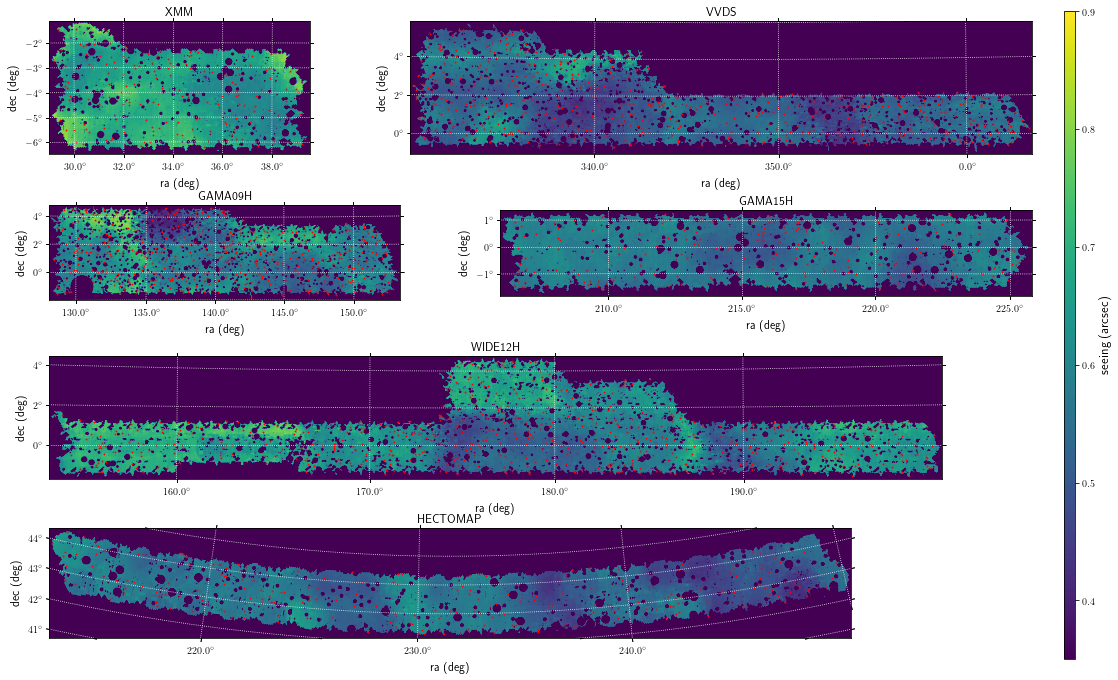

In [11]:
norm=mpl.colors.Normalize(vmin=0.35, vmax=0.90)

In [20]:
# Input map
for fieldname in mutilities.field_names:
    infname=os.path.join(inDir2,'%s_no_m.fits'%fieldname )
    data=pyfits.getdata(infname)
    ra,dec=utilities.get_radec(data)
    if fieldname=='VVDS':
        addR=(ra<300.).astype(int)*360
        ra+=addR
    v=data['i_inputcount_value']
    z=data['dnnz_photoz_best']
    
    gridInfo    =   cartesianGrid3D(parser)
    x,y=gridInfo.setupTanPlane(ra,dec)
    print(np.min(x),np.max(x))
    print(np.min(ra),np.max(ra))
    out=gridInfo.pixelize_data(x,y,z,v,ws=None)
    wcs_input_dict = {
        'CTYPE1': 'RA---TAN',
        'CUNIT1': 'deg',
        'CDELT1': 1./60.,
        'CRPIX1': gridInfo.nx//2+1,
        'CRVAL1': gridInfo.xcgrid[gridInfo.nx//2],
        'NAXIS1': gridInfo.nx,
        'CTYPE2': 'DEC--TAN',
        'CUNIT2': 'deg',
        'CDELT2': 1./60.,
        'CRPIX2': gridInfo.ny//2+1, #fits 1 based
        'CRVAL2': gridInfo.ycgrid[gridInfo.ny//2],
        'NAXIS2': gridInfo.ny
    }
    wcs_header = WCS(wcs_input_dict).to_header()
    
    pyfits.writeto(os.path.join(outDir,'%s_icountInMap.fits' %fieldname),out[0],header=wcs_header,overwrite=True)
    del data
    gc.collect()

29.086219696823967 39.420945858983316
29.093784804406443 39.41687484206933
128.0148302910242 153.3502141678189
128.1980673366667 153.1421325965732
152.66156939029062 200.89746604565678
153.9430872013283 199.59751411485658
206.0090069252839 225.7987689977325
206.10603477658103 225.70206609813968
330.0260677408365 363.6771613506724
330.46954174206724 363.20539481020353
217.69792926177686 245.36484428934793
212.5738517005094 250.20554438882596


XMM
(324, 632)
VVDS
(434, 2032)
GAMA09H
(412, 1532)
GAMA15H
(194, 1200)
WIDE12H
(400, 2906)
HECTOMAP
(228, 1672)


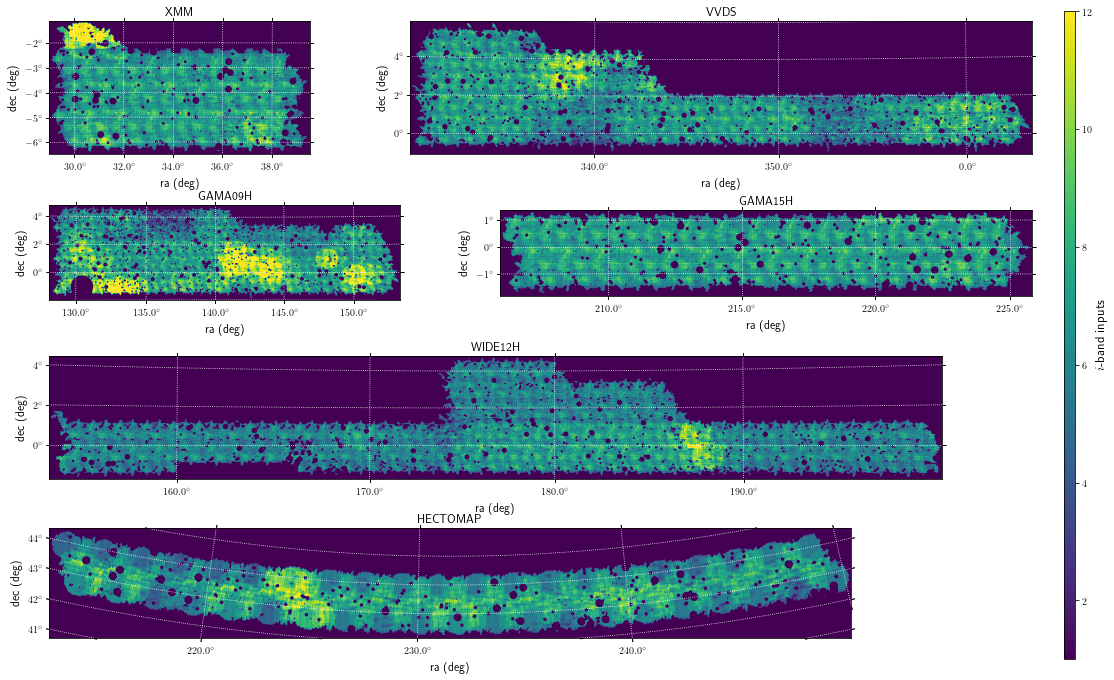

In [18]:
norm=mpl.colors.Normalize(vmin=1, vmax=12)
mapPlot('icountIn',r'$i$-band inputs',norm)

In [26]:
# Number map
for fieldname in mutilities.field_names:
    infname=os.path.join(inDir,'%s.fits'%fieldname )
    data=pyfits.getdata(infname)
    if fieldname=='VVDS':
        addR=(data['ra']<300.).astype(int)*360
        data['ra']+=addR
        
    z=data['dnn_zbest']
    ra=data['ra']
    dec=data['dec']

    gridInfo    =   cartesianGrid3D(parser)
    x,y=gridInfo.setupTanPlane(ra,dec)
    print(np.min(x),np.max(x))
    print(np.min(ra),np.max(ra))
    out=gridInfo.pixelize_data(x,y,z,v=None,ws=None)
    wcs_input_dict = {
        'CTYPE1': 'RA---TAN',
        'CUNIT1': 'deg',
        'CDELT1': 1./60.,
        'CRPIX1': gridInfo.nx//2+1,
        'CRVAL1': gridInfo.xcgrid[gridInfo.nx//2],
        'NAXIS1': gridInfo.nx,
        'CTYPE2': 'DEC--TAN',
        'CUNIT2': 'deg',
        'CDELT2': 1./60.,
        'CRPIX2': gridInfo.ny//2+1, #fits 1 based
        'CRVAL2': gridInfo.ycgrid[gridInfo.ny//2],
        'NAXIS2': gridInfo.ny
    }
    wcs_header = WCS(wcs_input_dict).to_header()
    pyfits.writeto(os.path.join(outDir,'%s_numMap.fits' %fieldname),out[0],header=wcs_header,overwrite=True)
    del out

    infname=os.path.join(inDir3,'%s_rand.fits'%fieldname )
    data=pyfits.getdata(infname)
    ra,dec=utilities.get_radec(data)
    if fieldname=='VVDS':
        addR=(ra<300.).astype(int)*360
        ra+=addR
    z=None
    v=None

    x,y=gridInfo.project_tan(ra,dec)
    print(np.min(x),np.max(x))
    print(np.min(ra),np.max(ra))
    out=gridInfo.pixelize_data(x,y,z,v,ws=None)/100.
    pyfits.writeto(os.path.join(outDir,'%s_areaMap.fits' %fieldname),out[0],header=wcs_header,overwrite=True)
    del out
    gc.collect()

29.086219696823967 39.420945858983316
29.093784804406443 39.41687484206933
29.083702813558208 39.42247094196762
29.09292710682664 39.41843307243197
128.0148302910242 153.3502141678189
128.1980673366667 153.1421325965732
128.00498971236348 153.35584493803776
128.1887085901093 153.14747053051806
152.66156939029062 200.89746604565678
153.9430872013283 199.59751411485658
152.66263384213286 200.8985721145535
153.94397218423742 199.5984523087405
206.0090069252839 225.7987689977325
206.10603477658103 225.70206609813968
206.00732545378318 225.7977811363075
206.10431204654154 225.70110733205502
330.0260677408365 363.6771613506724
330.46954174206724 363.20539481020353
330.0261519570822 363.67779899725224
330.4696274867077 363.20595175121997
217.69792926177686 245.36484428934793
212.5738517005094 250.20554438882596
217.69703702589186 245.37069204956308
212.5697136226671 250.20821683000787


XMM
(324, 632)
VVDS
(434, 2032)
GAMA09H
(412, 1532)
GAMA15H
(194, 1200)
WIDE12H
(400, 2906)
HECTOMAP
(228, 1672)


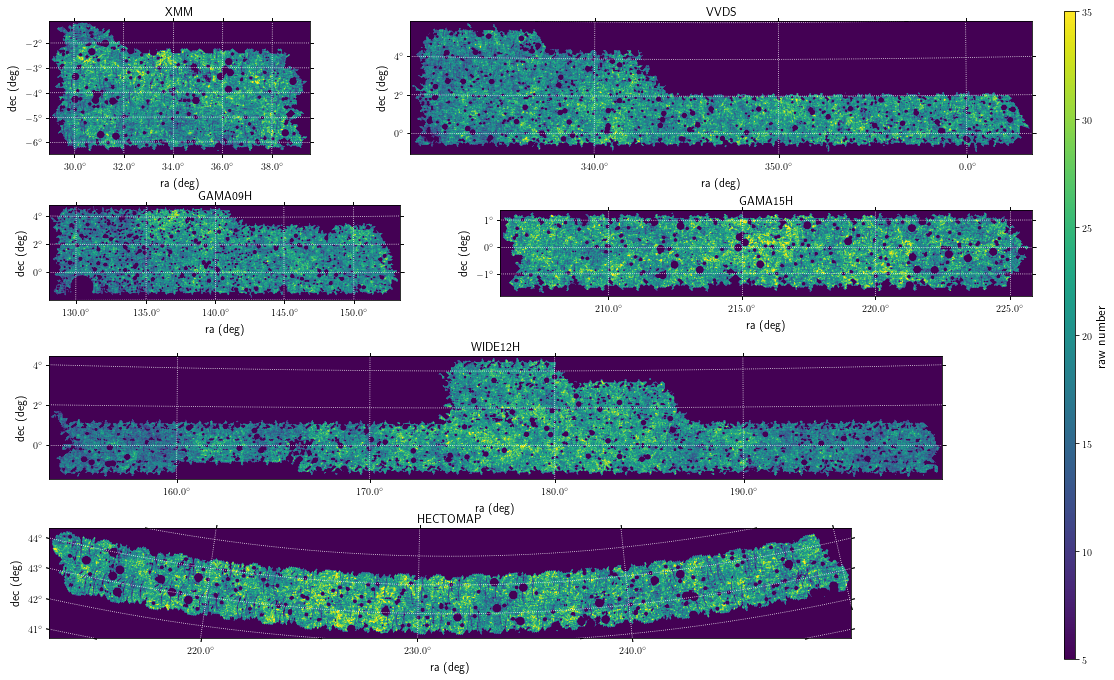

In [19]:
norm=mpl.colors.Normalize(vmin=5, vmax=35)
mapPlot('num','raw number',norm)

In [24]:
# Number map
extList={}
for fieldname in mutilities.field_names:
    infname=os.path.join(inDir,'%s.fits'%fieldname )
    data=pyfits.getdata(infname)
    if fieldname=='VVDS':
        addR=(data['ra']<300.).astype(int)*360
        data['ra']+=addR
    
    z=data['dnn_zbest']
    ra=data['ra']
    dec=data['dec']

    gridInfo    =   cartesianGrid3D(parser)
    x,y=gridInfo.setupTanPlane(ra,dec)
    ext=(gridInfo.ramin,gridInfo.ramax,gridInfo.decmin,gridInfo.decmax)
    print(np.min(x),np.max(x))
    print(np.min(ra),np.max(ra))
    out=gridInfo.pixelize_data(x,y,z,v=None,ws=0.4**2.*data['weight'])
    wcs_input_dict = {
        'CTYPE1': 'RA---TAN',
        'CUNIT1': 'deg',
        'CDELT1': 1./60.,
        'CRPIX1': gridInfo.nx//2+1,
        'CRVAL1': gridInfo.xcgrid[gridInfo.nx//2],
        'NAXIS1': gridInfo.nx,
        'CTYPE2': 'DEC--TAN',
        'CUNIT2': 'deg',
        'CDELT2': 1./60.,
        'CRPIX2': gridInfo.ny//2+1, #fits 1 based
        'CRVAL2': gridInfo.ycgrid[gridInfo.ny//2],
        'NAXIS2': gridInfo.ny
    }
    wcs_header = WCS(wcs_input_dict).to_header()

    pyfits.writeto(os.path.join(outDir,'%s_wsMap.fits' %fieldname),out[0],header=wcs_header,overwrite=True)
    del out
    gc.collect()

29.086219696823967 39.420945858983316
29.093784804406443 39.41687484206933
128.0148302910242 153.3502141678189
128.1980673366667 153.1421325965732
152.66156939029062 200.89746604565678
153.9430872013283 199.59751411485658
206.0090069252839 225.7987689977325
206.10603477658103 225.70206609813968
330.0260677408365 363.6771613506724
330.46954174206724 363.20539481020353
217.69792926177686 245.36484428934793
212.5738517005094 250.20554438882596


XMM
(324, 632)
VVDS
(434, 2032)
GAMA09H
(412, 1532)
GAMA15H
(194, 1200)
WIDE12H
(400, 2906)
HECTOMAP
(228, 1672)


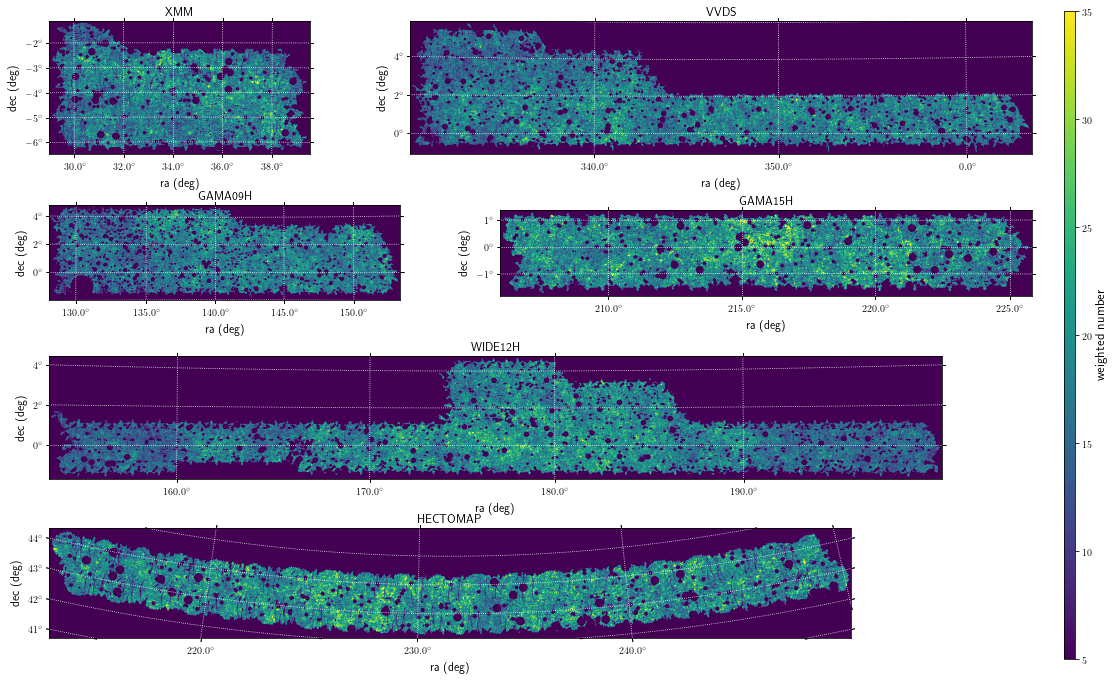

In [25]:
norm=mpl.colors.Normalize(vmin=5, vmax=35)
mapPlot('ws','weighted number',norm)

XMM
(324, 632)
VVDS
(434, 2032)
GAMA09H
(412, 1532)
GAMA15H
(194, 1200)
WIDE12H
(400, 2906)
HECTOMAP
(228, 1672)


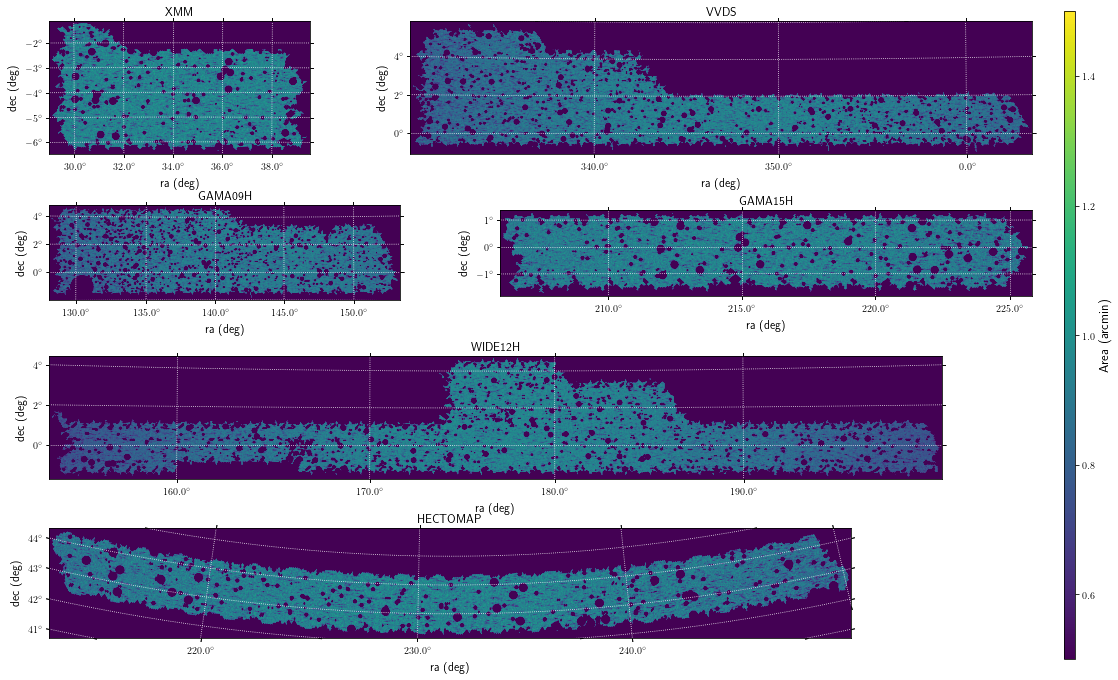

In [28]:
norm=mpl.colors.Normalize(vmin=0.5, vmax=1.5)
mapPlot('area','Area (arcmin)',norm)

In [30]:
for fieldname in mutilities.field_names:
    map1=pyfits.getdata(os.path.join(outDir,'%s_numMap.fits' %fieldname))
    map2=pyfits.getdata(os.path.join(outDir,'%s_wsMap.fits' %fieldname))
    mapA=pyfits.getdata(os.path.join(outDir,'%s_areaMap.fits' %fieldname))
    wcs_header=pyfits.getheader(os.path.join(outDir,'%s_numMap.fits' %fieldname))
    msk=(mapA>0)
    mapp1=np.zeros(map1.shape)
    mapp2=np.zeros(map1.shape)
    mapp1[msk]=map1[msk]/mapA[msk]
    mapp2[msk]=map2[msk]/mapA[msk]
    print(np.average(mapp1[msk]),np.average(mapp2[msk]))
    pyfits.writeto(os.path.join(outDir,'%s_nDensMap.fits' %fieldname),map1,header=wcs_header,overwrite=True)
    pyfits.writeto(os.path.join(outDir,'%s_wDensMap.fits' %fieldname),map2,header=wcs_header,overwrite=True)

21.952611485984683 19.1004353680351
22.59532511479435 20.181680925667756
23.152600799524 20.70198842054855
24.223548217786565 21.876292744386294
23.352825085661298 20.30806380451982
24.15023151395952 21.68515532761097


XMM
(324, 632)
VVDS
(434, 2032)
GAMA09H
(412, 1532)
GAMA15H
(194, 1200)
WIDE12H
(400, 2906)
HECTOMAP
(228, 1672)


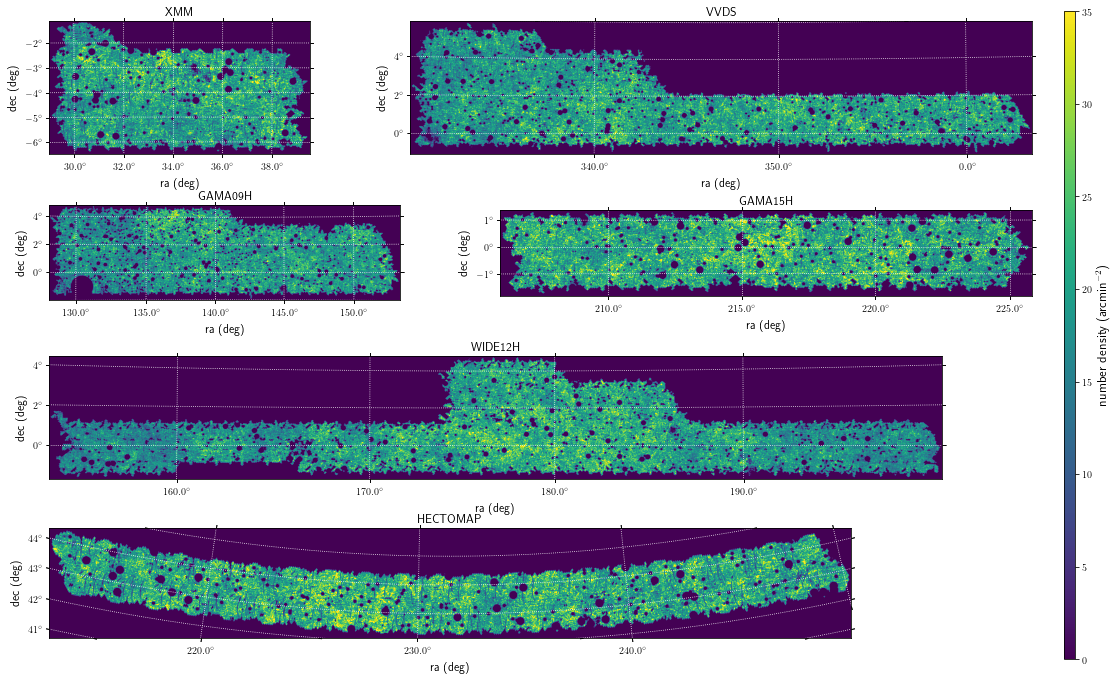

In [35]:
norm=mpl.colors.Normalize(vmin=0, vmax=35)
mapPlot('nDens','number density (arcmin$^{-2}$)',norm)

XMM
(324, 632)
VVDS
(434, 2032)
GAMA09H
(412, 1532)
GAMA15H
(194, 1200)
WIDE12H
(400, 2906)
HECTOMAP
(228, 1672)


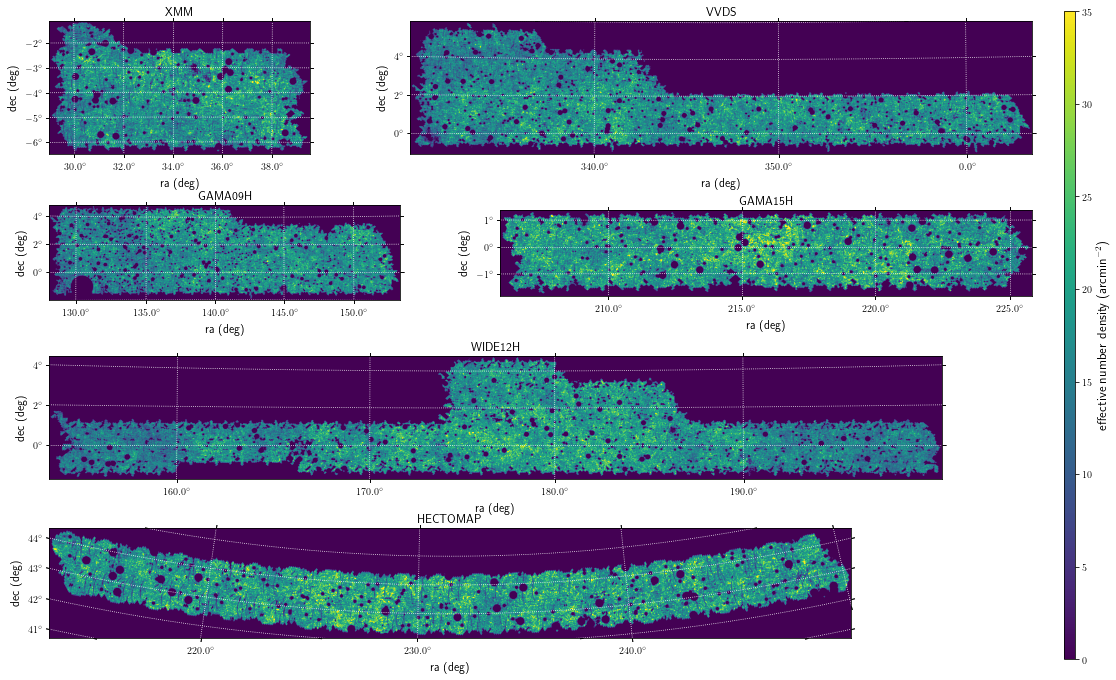

In [36]:
norm=mpl.colors.Normalize(vmin=0, vmax=35)
mapPlot('wDens','effective number density (arcmin$^{-2}$)',norm)

In [58]:
# Hex keys for the color scheme for shear catalog paper
plot_colors = {
    'GAMA09H' : '#d73027',
    'GAMA15H' : '#fc8d59',
    'HECTOMAP': '#fee090',
    'VVDS'    : '#000000',
    'WIDE12H' : '#91bfdb',
    'XMM'     : '#4575b4'
    }

pltList=['XMM','VVDS','GAMA09H','GAMA15H','WIDE12H','HECTOMAP']
xList={}
yList={}
cmax=0.
for fieldname in pltList:
    c=plot_colors[fieldname]
    datax=pyfits.getdata(os.path.join(outDir,'%s_fwhmMap.fits' %fieldname))
    datay=pyfits.getdata(os.path.join(outDir,'%s_wDensMap.fits' %fieldname))
    mask=datay>2.
    datax=datax[mask]
    datay=datay[mask]
    ind=np.arange(len(datay))
    np.random.shuffle(ind)
    print(fieldname,np.average(datay))
    xList.update({fieldname:datax[ind]})
    yList.update({fieldname:datay[ind]})

XMM 17.378594204274727
VVDS 17.337324096022837
GAMA09H 17.246217952314325
GAMA15H 19.281535082591404
WIDE12H 17.590747942368534
HECTOMAP 19.038257241472927


The PostScript backend does not support transparency; partially transparent artists will be rendered opaque.
The PostScript backend does not support transparency; partially transparent artists will be rendered opaque.


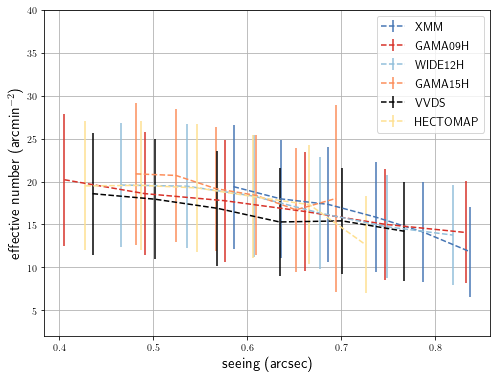

In [74]:
plt.close()
fig=plt.figure(figsize=(8,6))
ax=fig.add_subplot(1,1,1)
for fieldname in utilities.field_names:
    #ax.scatter(xList[fieldname][0::20],yList[fieldname][0::20],s=0.05,c=plot_colors[fieldname])
    up,xx=np.histogram(xList[fieldname],bins=6,weights=yList[fieldname])
    down=np.histogram(xList[fieldname],bins=6)[0]
    up2=np.histogram(xList[fieldname],bins=6,weights=yList[fieldname]**2.)[0]
    ave=up/down
    x2=up2/down
    std=np.sqrt(x2-ave**2.)
    xx=(xx[1:]+xx[:-1])/2.
    ax.errorbar(xx,ave,std,ls='--',c=plot_colors[fieldname],label=fieldname)
ax.set_ylim(2.,40.)
ax.set_xlabel('seeing (arcsec)',fontsize=15)
ax.set_ylabel('effective number (arcmin$^{-2}$)',fontsize=15)
plt.legend(loc='upper right',fontsize=12)
plt.grid()
fig.savefig(os.path.join(outDir,'ws-seeing.png'))
fig.savefig(os.path.join(outDir,'ws-seeing.eps'))